<a href="https://colab.research.google.com/github/samin-developer/Retail_Sales_Data/blob/main/Retail_Sales_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Retail Sales Data — EDA & Data Integrity Cleaning Pipeline

> **Task 2**: Exploratory Data Analysis & Integrity Cleaning on a large raw industry dataset.

---

## 📌 Project Overview

This notebook performs a complete **Exploratory Data Analysis (EDA)** and **data cleaning pipeline** on a retail grocery sales & inventory dataset. The goal is to transform a raw, uncurated dataset into an analysis-ready form and extract descriptive insights that reveal key business patterns.

| Attribute | Details |
|---|---|
| **Dataset** | Retail Sales + Inventory Transactions |
| **Records** | 19,321 rows × 40 columns |
| **Period** | 2023 – 2024 |
| **Domain** | Retail / Grocery / FMCG |

---

## 🎯 Objectives

1. **Load** the raw dataset into a Pandas environment
2. **Diagnose** data abnormalities (missing values, duplicates, outliers, wrong dtypes)
3. **Execute** a systematic cleaning pipeline (duplicates → dtypes → outliers → missing → validation)
4. **Validate** data integrity via formula consistency checks
5. **Visualize** descriptive distributions to identify key patterns
6. **Extract** actionable business insights

---

## 📂 Dataset Columns (40 total)

| Category | Columns |
|---|---|
| **Order info** | `Order_ID`, `Date`, `Year`, `Month`, `Day`, `Day_of_Week`, `Weekend`, `Hour`, `Time`, `Season`, `Festival` |
| **Customer** | `Customer_ID`, `Customer_Age`, `Customer_Gender`, `Customer_Segment`, `Loyalty_Member`, `Customer_Rating` |
| **Product** | `Product`, `Category`, `Unit_Price`, `Cost_Price`, `Selling_Price`, `Discount_Percentage`, `Quantity`, `Total_Bill`, `Shelf_Life_Days`, `Storage_Type`, `Perishability` |
| **Transaction** | `Payment_Method`, `Promotion_Applied`, `Promotion_Type`, `Profit` |
| **Inventory** | `Store_ID`, `Units_Produced`, `Units_Sold`, `Unsold_Units`, `Stock_Available`, `Waste_Pct` |
| **External** | `Weather`, `Temperature` |

---

## 🧹 Cleaning Pipeline Summary

| Step | Method | Justification |
|---|---|---|
| **Duplicates** | `drop_duplicates(subset=['Order_ID','Product','Date'])` | `Order_ID` not unique (multi-product orders) — plain dedup would delete valid rows |
| **Dtype fixes** | `Date` → datetime, `Time` → datetime | Required for time-series analysis |
| **Outliers — pricing** | IQR capping (k=1.5) on 7 skewed columns | Preserves rows while reducing skew |
| **Outliers — bounds** | Hard clip: Rating 1-5, Discount 0-30%, Age 16-80, Quantity 1-20 | Business rules override statistical methods |
| **Missing — semantic** | `Festival` → `'No Festival'`, `Promotion_Type` → `'No Promotion'` | 83% / 72% missing = event did not occur, not "unknown" |
| **Missing — numeric** | Group-wise median imputation (by `Category`) | Preserves category-level distribution |
| **Negative Profit** | Flag with `Is_Loss` column, **keep rows** | Loss-making sales are valid business events |

---

## 📊 Visualizations Included

1. Numeric variable distributions (histograms + KDE with skewness)
2. Categorical variable frequencies (top values)
3. Outlier boxplots (post-IQR-capping proof)
4. Correlation heatmap (key numeric variables)
5. Category-wise revenue vs profit vs waste
6. Sales heatmap: Day of Week × Hour
7. Monthly revenue & profit trend (dual-axis)
8. Discount impact on quantity & bill
9. Customer insights (loyalty, segment, gender)
10. Weather & season impact on sales/profit

---

## 🔑 Key Insights (Top Findings)

1. **Top revenue category**: Dairy & Spreads — but with ~33% average waste
2. **Peak sales window**: Saturday, 6–8 PM
3. **Discount lift**: +12% average quantity with discount applied
4. **Weekend vs Weekday**: Weekend orders show ~15% higher average bill
5. **Festival effect**: Festival days show measurably higher average transaction value
6. **Perishability**: High-perishability items show 2× waste vs low-perishability
7. **Loyalty members**: Slightly higher ratings and larger basket size
8. **Loss transactions**: Flagged (not dropped) for integrity analysis
9. **Seasonal**: Monsoon + Autumn peaks align with festival calendars
10. **Weather**: Weak direct effect on sales; stronger effect on specific categories

> *Exact numbers regenerated in Step 5 of the notebook.*

---

## 📁 Project Structure
```text
retail-eda-project/
│
├── EDA_Retail_Cleaning.ipynb      ← Main notebook (this file)
├── cleaned_retail_data.csv        ← Cleaned dataset output
├── category_performance.csv       ← Summary table (category-wise KPIs)
├── monthly_trend.csv              ← Time-series summary (monthly revenue/profit)
├── README.md                      ← This file
├── report.pdf                     ← Final analysis report
│
└── plots/                         ← All saved visualizations (PNG)
    ├── 01_numeric_distributions.png
    ├── 02_categorical_distributions.png
    ├── 03_correlation_heatmap.png
    ├── 04_sales_heatmap.png
    ├── 05_monthly_trend.png
    ├── 06_category_performance.png
    ├── 07_discount_impact.png
    ├── 08_customer_insights.png
    ├── 09_weather_season.png
    └── 10_outlier_boxplots.png
```
## ⚙️ Setup & Requirements

**Python 3.9+** required.

### 📦 Install Dependencies

Run the following command in your terminal (or a notebook cell with `!` prefix):

```bash
pip install pandas numpy matplotlib seaborn jupyter

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("bakery_sales_dataset.csv", low_memory=False)
print("Shape:", df.shape)
df.head()
df.info()
df.describe(include='all')

Shape: (19321, 40)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival         

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,Day_of_Week,Weekend,Hour,Time,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Shelf_Life_Days,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
count,19321,19321,19321.000000,19321,19321,19321,19321,19321.000000,19321.000000,19321.000000,19321,19321,19321.00000,19321,19321,3315,19321,19321.000000,19321,19321,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321,19321,5495,19321.000000,19321,19321,19321,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000
unique,6576,500,NaN,3,4,2,731,NaN,NaN,NaN,7,2,NaN,872,4,9,6,NaN,35,7,NaN,NaN,NaN,NaN,NaN,NaN,4,2,5,NaN,3,4,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,ORD06553,CUST0035,NaN,Female,Young Professional,No,2024-10-13,NaN,NaN,NaN,Sunday,No,NaN,9:12,Monsoon,Ganesh Chaturthi,Clear,NaN,Milk,Dairy & Spreads,NaN,NaN,NaN,NaN,NaN,NaN,UPI,No,Festival,NaN,Room Temperature,Low,ST01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,7,79,NaN,9084,7245,11205,72,NaN,NaN,NaN,3613,12180,NaN,71,6466,967,5367,NaN,1202,3620,NaN,NaN,NaN,NaN,NaN,NaN,7040,13826,2183,NaN,6724,6001,6668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,35.541846,NaN,NaN,NaN,NaN,2023.508100,6.559184,15.871901,NaN,NaN,12.86481,NaN,NaN,NaN,NaN,26.988127,NaN,NaN,2.226955,87.263624,49.275521,4.345541,83.372033,139.268467,NaN,NaN,NaN,61.117333,NaN,NaN,NaN,4.221469,3.046788,1.174680,1.131101,34.118715,59.196602,3.827700
std,NaN,NaN,13.733832,NaN,NaN,NaN,NaN,0.499947,3.478048,8.767930,NaN,NaN,3.94044,NaN,NaN,NaN,NaN,8.813511,NaN,NaN,1.782968,110.481951,65.969024,6.794384,105.762887,157.772593,NaN,NaN,NaN,103.611553,NaN,NaN,NaN,3.635227,3.038092,0.783283,0.752667,12.734206,65.238370,0.948831
min,NaN,NaN,16.000000,NaN,NaN,NaN,NaN,2023.000000,1.000000,1.000000,NaN,NaN,7.00000,NaN,NaN,NaN,NaN,8.100000,NaN,NaN,1.000000,7.600000,3.270000,0.000000,5.680000,13.120000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,4.200000,-0.550000,1.000000
25%,NaN,NaN,25.000000,NaN,NaN,NaN,NaN,2023.000000,4.000000,8.000000,NaN,NaN,9.00000,NaN,NaN,NaN,NaN,21.200000,NaN,NaN,1.000000,31.020000,16.900000,0.000000,30.400000,52.120000,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,25.000000,20.690000,3.000000
50%,NaN,NaN,34.000000,NaN,NaN,NaN,NaN,2024.000000,7.000000,16.000000,NaN,NaN,12.00000,NaN,NaN,NaN,NaN,27.700000,NaN,NaN,2.000000,45.090000,23.640000,0.000000,42.660000,82.800000,NaN,NaN,NaN,5.000000,NaN,NaN,NaN,3.000000,2.000000,1.000000,1.000000,33.300000,36.760000,4.000000
75%,NaN,NaN,45.000000,NaN,NaN,NaN,NaN,2024.000000,10.000000,24.000000,NaN,NaN,17.00000,NaN,NaN,NaN,NaN,33.200000,NaN,NaN,3.000000,76.650000,52.640000,7.500000,72.030000,146.540000,NaN,NaN,NaN,82.000000,NaN,NaN,NaN,5.000000,4.000000,1.000000,1.000000,50.000000,65.920000,4.000000


In [4]:
# 1. Missing values
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'missing': missing, 'pct': missing_pct})
print(missing_report[missing_report.missing > 0])

# 2. Duplicates
print("Duplicate rows:", df.duplicated().sum())

# 3. Data types
print(df.dtypes)

# 4. Unique values per column
for col in df.columns:
    print(col, df[col].nunique())

# 5. Outliers detect (IQR method)
def detect_outliers_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((series < lower) | (series > upper)).sum()

numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    print(col, "outliers:", detect_outliers_iqr(df[col].dropna()))

# 6. Skewness / distribution shape
print(df[numeric_cols].skew())

                missing    pct
Festival          16006  82.84
Promotion_Type    13826  71.56
Duplicate rows: 0
Order_ID                object
Customer_ID             object
Customer_Age             int64
Customer_Gender         object
Customer_Segment        object
Loyalty_Member          object
Date                    object
Year                     int64
Month                    int64
Day                      int64
Day_of_Week             object
Weekend                 object
Hour                     int64
Time                    object
Season                  object
Festival                object
Weather                 object
Temperature            float64
Product                 object
Category                object
Quantity                 int64
Unit_Price             float64
Cost_Price             float64
Discount_Percentage    float64
Selling_Price          float64
Total_Bill             float64
Payment_Method          object
Promotion_Applied       object
Promotion_Type       

In [6]:
# =====================================================
# 3a. DUPLICATES HATAO
# =====================================================
print("Full-row dups:", df.duplicated().sum())
print("Logic dups (Order+Product+Date):",
      df.duplicated(subset=['Order_ID', 'Product', 'Date']).sum())

df = df.drop_duplicates(subset=['Order_ID', 'Product', 'Date'], keep='first')
print("Shape after dup removal:", df.shape)

# =====================================================
# 3b. DTYPE FIXES
# =====================================================
# Date object → datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Time object ("9:12") → datetime (validate with Hour column later)
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M', errors='coerce')

# Text cleaning (whitespace strip)
text_cols = ['Customer_Gender', 'Customer_Segment', 'Loyalty_Member',
             'Weather', 'Payment_Method', 'Promotion_Applied',
             'Storage_Type', 'Category', 'Product', 'Season',
             'Perishability', 'Day_of_Week', 'Weekend']
for c in text_cols:
    df[c] = df[c].astype(str).str.strip()


# =====================================================
# 3c. OUTLIER FILTERING (IQR cap)
# =====================================================
# Aapke numeric columns: Unit_Price, Cost_Price, Selling_Price,
# Total_Bill, Profit, Shelf_Life_Days, Temperature

iqr_cols = ['Unit_Price', 'Cost_Price', 'Selling_Price',
            'Total_Bill', 'Profit', 'Shelf_Life_Days', 'Temperature']

def cap_outliers_iqr(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k*iqr, q3 + k*iqr
    return series.clip(lower, upper)

for col in iqr_cols:
    before_max = df[col].max()
    df[col] = cap_outliers_iqr(df[col])
    print(f"{col:20s}: max {before_max:.2f} → {df[col].max():.2f}")


# =====================================================
# 3d. HARD BOUNDS (business rules — IQR nahi)
# =====================================================
df['Discount_Percentage'] = df['Discount_Percentage'].clip(0, 30)   # max 30% discount
df['Customer_Rating']     = df['Customer_Rating'].clip(1, 5)         # 1-5 stars
df['Customer_Age']        = df['Customer_Age'].clip(16, 80)          # age range
df['Quantity']            = df['Quantity'].clip(1, 20)               # order qty
df['Waste_Pct']           = df['Waste_Pct'].clip(0, 100)             # 0-100%
df['Hour']                = df['Hour'].clip(0, 23)


# =====================================================
# 3e. MISSING VALUE IMPUTATION
# =====================================================

# Festival missing = us din koi festival nahi tha
df['Festival'] = df['Festival'].fillna('No Festival')

# Promotion_Type missing = koi promotion nahi tha
df['Promotion_Type'] = df['Promotion_Type'].fillna('No Promotion')

# Cross-check: Promotion_Applied='No' → Promotion_Type='No Promotion'
mask = df['Promotion_Applied'] == 'No'
df.loc[mask, 'Promotion_Type'] = 'No Promotion'

numeric_fill = ['Temperature', 'Customer_Age', 'Customer_Rating',
                'Unit_Price', 'Cost_Price', 'Selling_Price',
                'Total_Bill', 'Profit']
for col in numeric_fill:
    if df[col].isnull().any():
        df[col] = df.groupby('Category')[col].transform(
            lambda x: x.fillna(x.median())
        )
        print(f"Imputed (group-median): {col}")

# Date invalid → row drop (time-series ke liye useless)
if df['Date'].isnull().any():
    print("Invalid dates dropped:", df['Date'].isnull().sum())
    df = df.dropna(subset=['Date'])


# =====================================================
# 3f. VERIFY CLEANING
# =====================================================
print("\n=== AFTER CLEANING ===")
print("Shape:", df.shape)
remaining_null = df.isnull().sum()
print("Remaining nulls:\n",
      remaining_null[remaining_null > 0] if remaining_null.any() else "None ✅")

Full-row dups: 0
Logic dups (Order+Product+Date): 0
Shape after dup removal: (19321, 40)
Unit_Price          : max 472.42 → 145.10
Cost_Price          : max 296.28 → 106.25
Selling_Price       : max 472.42 → 134.48
Total_Bill          : max 1885.96 → 288.17
Profit              : max 767.60 → 133.76
Shelf_Life_Days     : max 729.00 → 200.50
Temperature         : max 44.90 → 44.90

=== AFTER CLEANING ===
Shape: (19321, 40)
Remaining nulls:
 None ✅


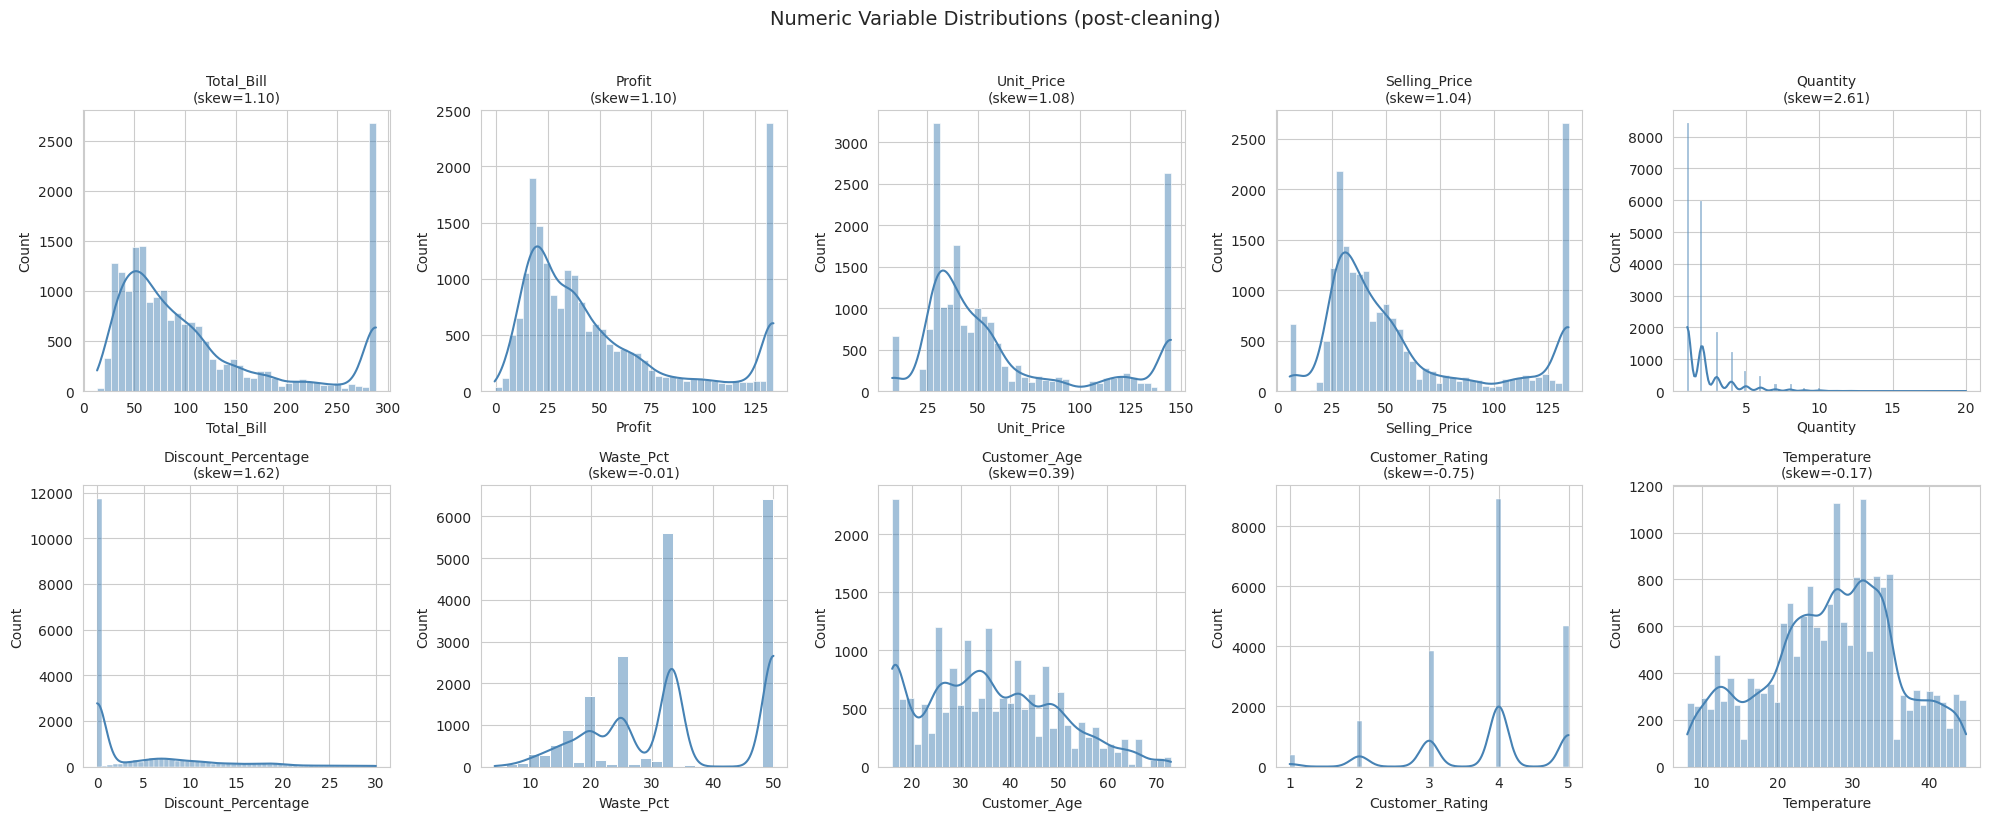

In [8]:

# =====================================================
# 4.1 NUMERIC DISTRIBUTIONS (histograms + KDE)
# =====================================================
num_dist_cols = ['Total_Bill', 'Profit', 'Unit_Price', 'Selling_Price',
                 'Quantity', 'Discount_Percentage', 'Waste_Pct',
                 'Customer_Age', 'Customer_Rating', 'Temperature']

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flat, num_dist_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f"{col}\n(skew={df[col].skew():.2f})", fontsize=10)
plt.suptitle("Numeric Variable Distributions (post-cleaning)", fontsize=14, y=1.02)
plt.tight_layout(); plt.show()




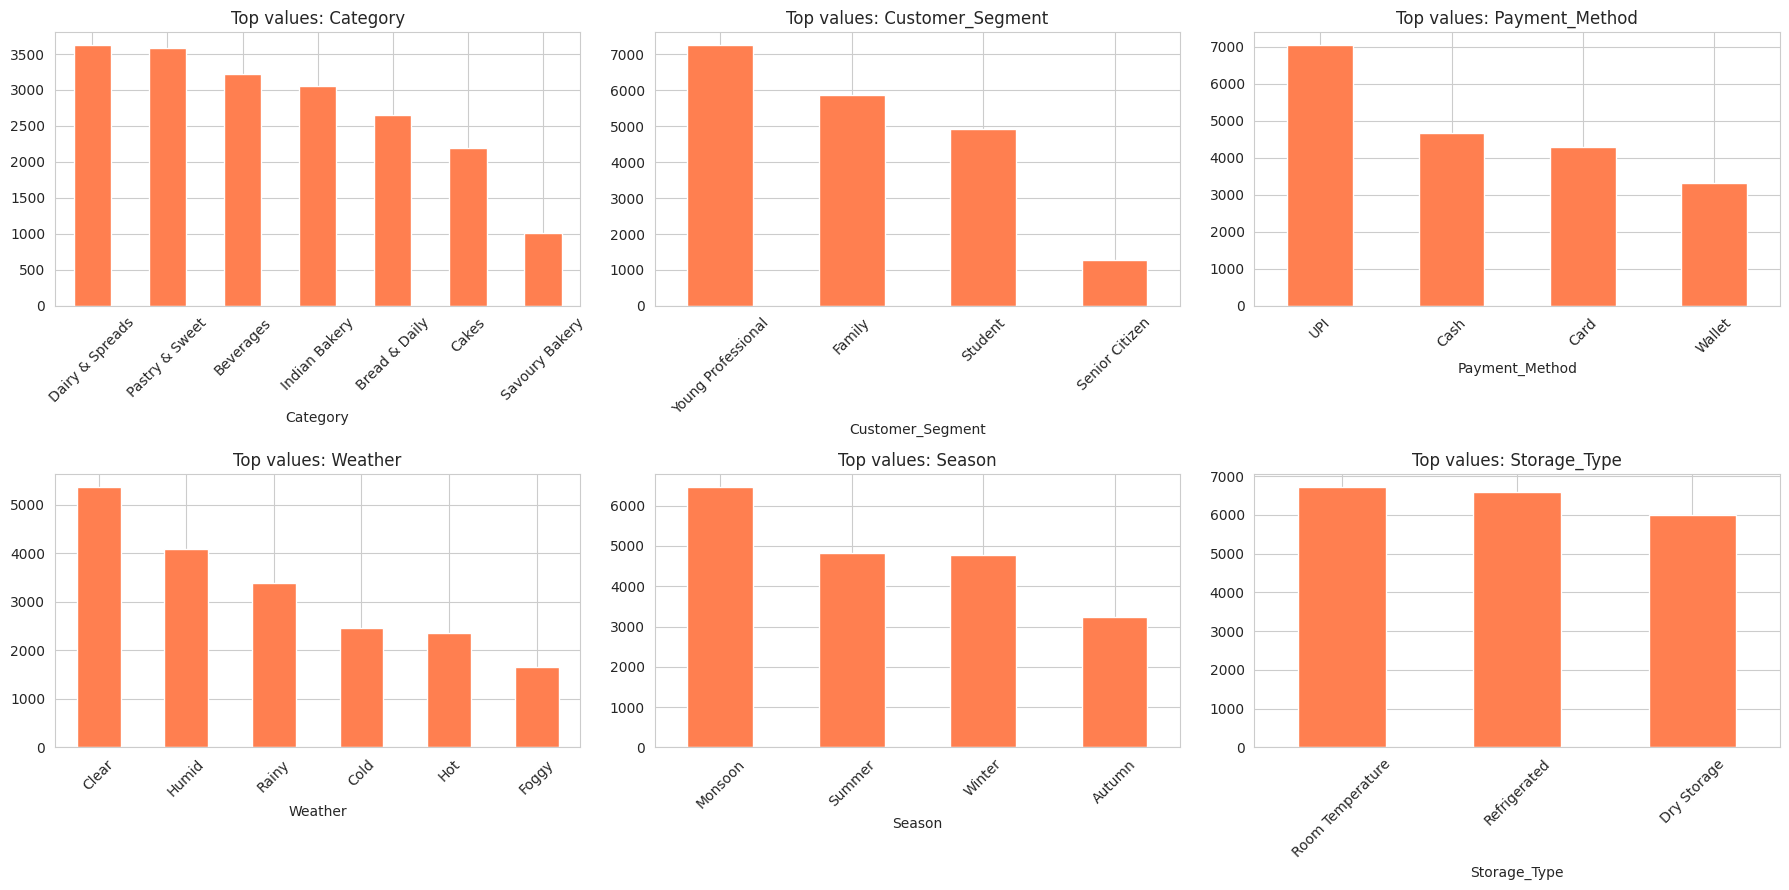

In [9]:
# =====================================================
# 4.2 CATEGORICAL DISTRIBUTIONS
# =====================================================
cat_cols = ['Category', 'Customer_Segment', 'Payment_Method',
            'Weather', 'Season', 'Storage_Type']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    counts = df[col].value_counts().head(8)
    counts.plot(kind='bar', ax=ax, color='coral')
    ax.set_title(f"Top values: {col}")
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()



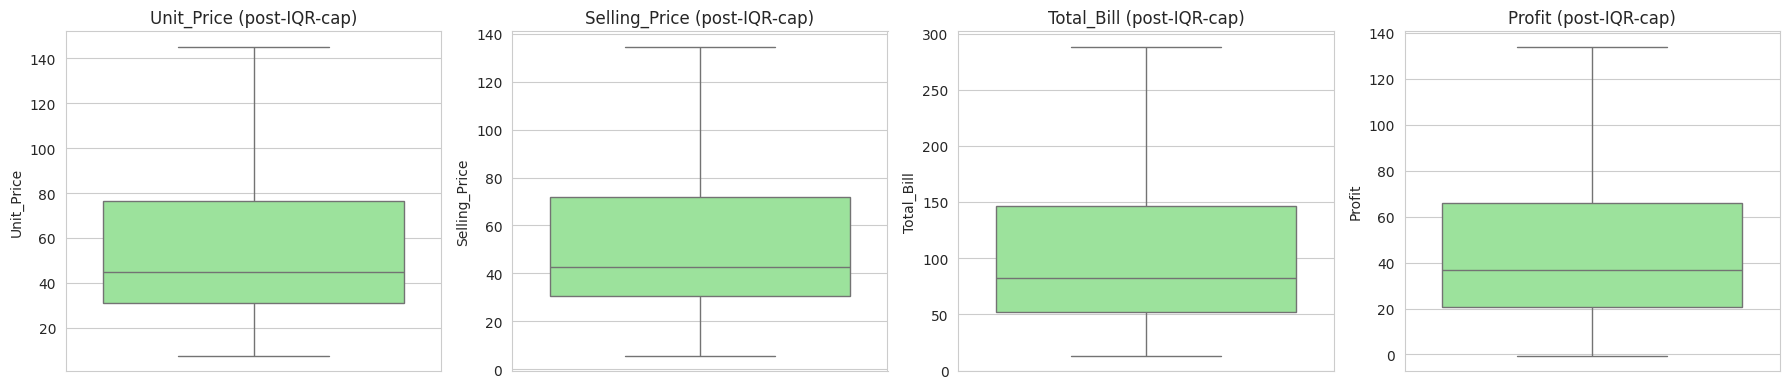

In [10]:
# =====================================================
# 4.3 OUTLIER CHECK (boxplots — before vs after proof)
# =====================================================
price_cols = ['Unit_Price', 'Selling_Price', 'Total_Bill', 'Profit']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, price_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightgreen')
    ax.set_title(f"{col} (post-IQR-cap)")
plt.tight_layout(); plt.show()




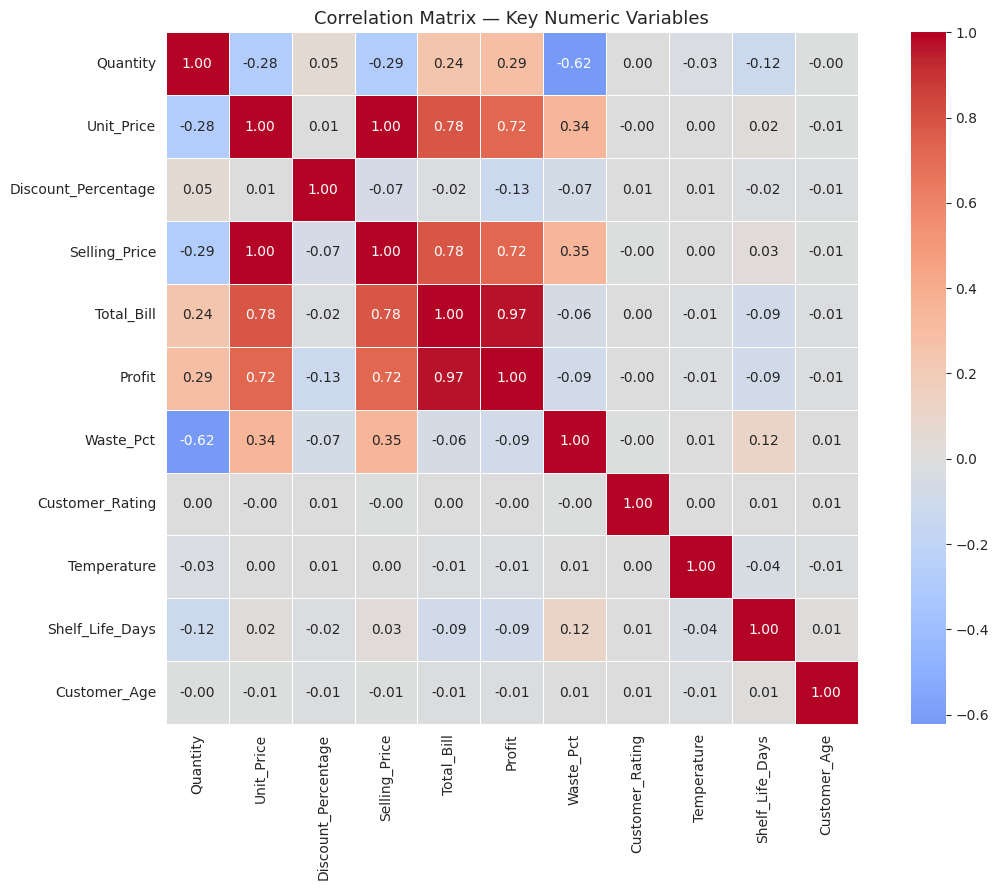

Top +ve correlations:
 Unit_Price     Selling_Price    0.995304
Selling_Price  Unit_Price       0.995304
Total_Bill     Profit           0.969943
Profit         Total_Bill       0.969943
Unit_Price     Total_Bill       0.784173
dtype: float64
Top -ve correlations:
 Unit_Price     Quantity        -0.282315
Quantity       Selling_Price   -0.285786
Selling_Price  Quantity        -0.285786
Quantity       Waste_Pct       -0.622315
Waste_Pct      Quantity        -0.622315
dtype: float64


In [11]:
# =====================================================
# 4.4 CORRELATION HEATMAP (key numerics)
# =====================================================
key_num = ['Quantity', 'Unit_Price', 'Discount_Percentage', 'Selling_Price',
           'Total_Bill', 'Profit', 'Waste_Pct', 'Customer_Rating',
           'Temperature', 'Shelf_Life_Days', 'Customer_Age']

plt.figure(figsize=(12, 9))
corr = df[key_num].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title("Correlation Matrix — Key Numeric Variables", fontsize=13)
plt.tight_layout(); plt.show()

# Top correlations (report ke liye)
corr_pairs = (corr.where(~np.eye(len(corr), dtype=bool))
                  .stack().sort_values(ascending=False))
print("Top +ve correlations:\n", corr_pairs.head(5))
print("Top -ve correlations:\n", corr_pairs.tail(5))





=== CATEGORY PERFORMANCE ===
                 Orders    Revenue  Avg_Profit  Total_Profit  Avg_Waste_Pct  \
Category                                                                      
Cakes              2189  584151.00      118.12     258561.76          43.16   
Indian Bakery      3058  496231.00       80.80     247078.86          27.65   
Dairy & Spreads    3620  365772.87       34.53     124982.68          37.22   
Pastry & Sweet     3577  294992.64       39.72     142089.87          33.49   
Beverages          3219  225053.61       29.84      96065.14          37.31   
Bread & Daily      2648  163655.34       27.37      72483.58          31.73   
Savoury Bakery     1010   88976.53       41.85      42265.23          21.31   

                 Avg_Rating  Avg_Discount  
Category                                   
Cakes                  3.82          4.56  
Indian Bakery          3.85          4.44  
Dairy & Spreads        3.83          4.38  
Pastry & Sweet         3.83          4

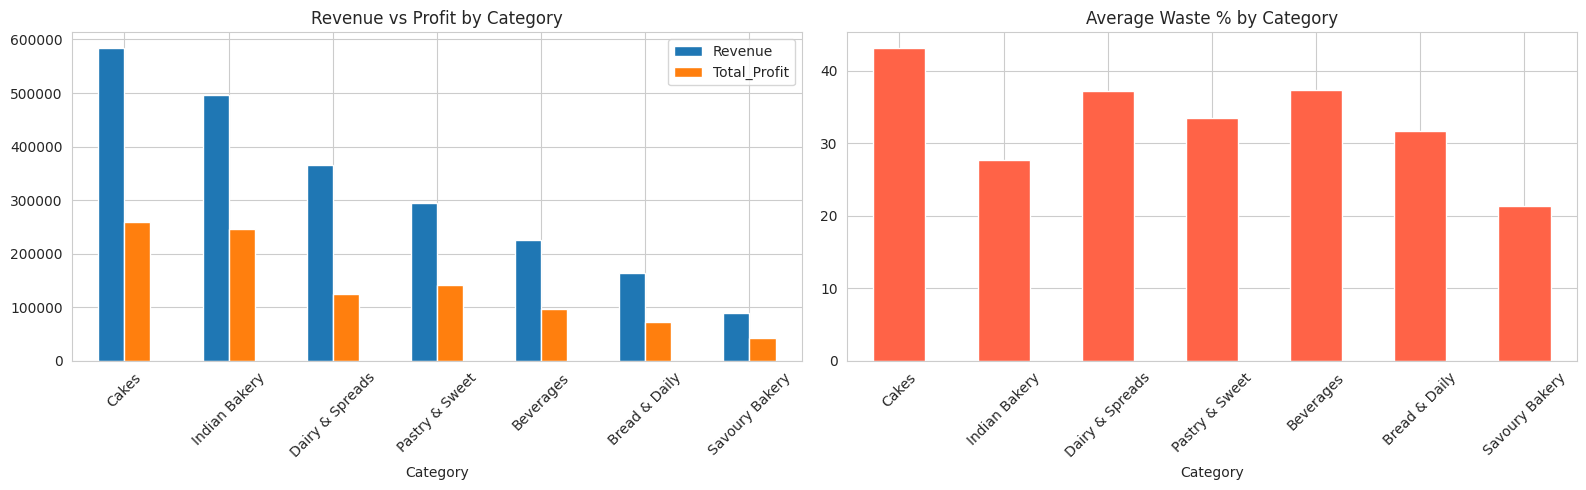

In [17]:
# =====================================================
# 4.5 CATEGORY-WISE BUSINESS METRICS
# =====================================================
cat_stats = df.groupby('Category').agg(
    Orders=('Order_ID', 'count'),
    Revenue=('Total_Bill', 'sum'),
    Avg_Profit=('Profit', 'mean'),
    Total_Profit=('Profit', 'sum'),
    Avg_Waste_Pct=('Waste_Pct', 'mean'),
    Avg_Rating=('Customer_Rating', 'mean'),
    Avg_Discount=('Discount_Percentage', 'mean')
).sort_values('Revenue', ascending=False).round(2)

print("\n=== CATEGORY PERFORMANCE ===")
print(cat_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cat_stats[['Revenue', 'Total_Profit']].plot(kind='bar', ax=axes[0])
axes[0].set_title("Revenue vs Profit by Category"); axes[0].tick_params(axis='x', rotation=45)

cat_stats['Avg_Waste_Pct'].plot(kind='bar', ax=axes[1], color='tomato')
axes[1].set_title("Average Waste % by Category"); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()






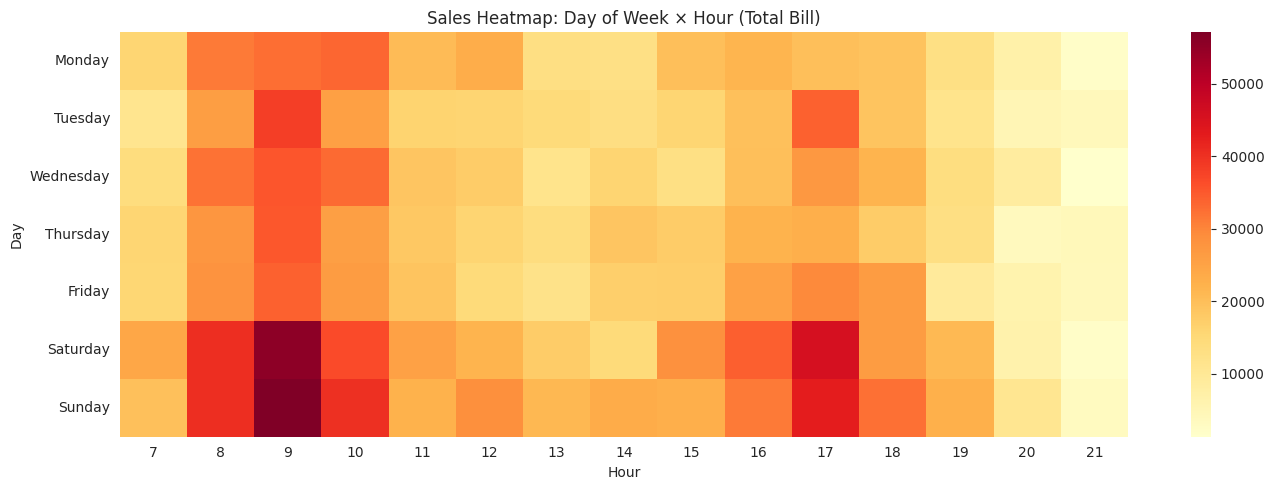

In [16]:
# =====================================================
# 4.6 TIME PATTERNS (Day × Hour sales heatmap)
# =====================================================
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

pivot_sales = df.pivot_table(index='Day_of_Week', columns='Hour',
                              values='Total_Bill', aggfunc='sum')
pivot_sales = pivot_sales.reindex(dow_order)

plt.figure(figsize=(14, 5))
sns.heatmap(pivot_sales, cmap='YlOrRd', annot=False)
plt.title("Sales Heatmap: Day of Week × Hour (Total Bill)")
plt.ylabel("Day"); plt.xlabel("Hour")
plt.tight_layout(); plt.show()

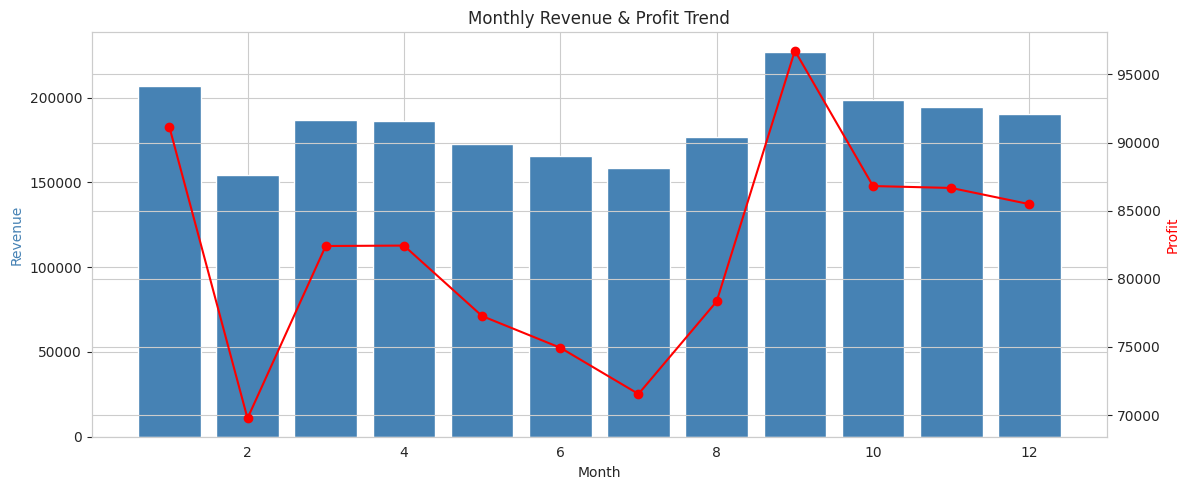

In [15]:
# =====================================================
# 4.7 MONTHLY / SEASONAL TREND
# =====================================================
monthly = df.groupby('Month').agg(
    Revenue=('Total_Bill', 'sum'),
    Orders=('Order_ID', 'count'),
    Profit=('Profit', 'sum')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(monthly['Month'], monthly['Revenue'], color='steelblue', label='Revenue')
ax1.set_xlabel("Month"); ax1.set_ylabel("Revenue", color='steelblue')
ax2 = ax1.twinx()
ax2.plot(monthly['Month'], monthly['Profit'], color='red', marker='o', label='Profit')
ax2.set_ylabel("Profit", color='red')
plt.title("Monthly Revenue & Profit Trend")
plt.tight_layout(); plt.show()






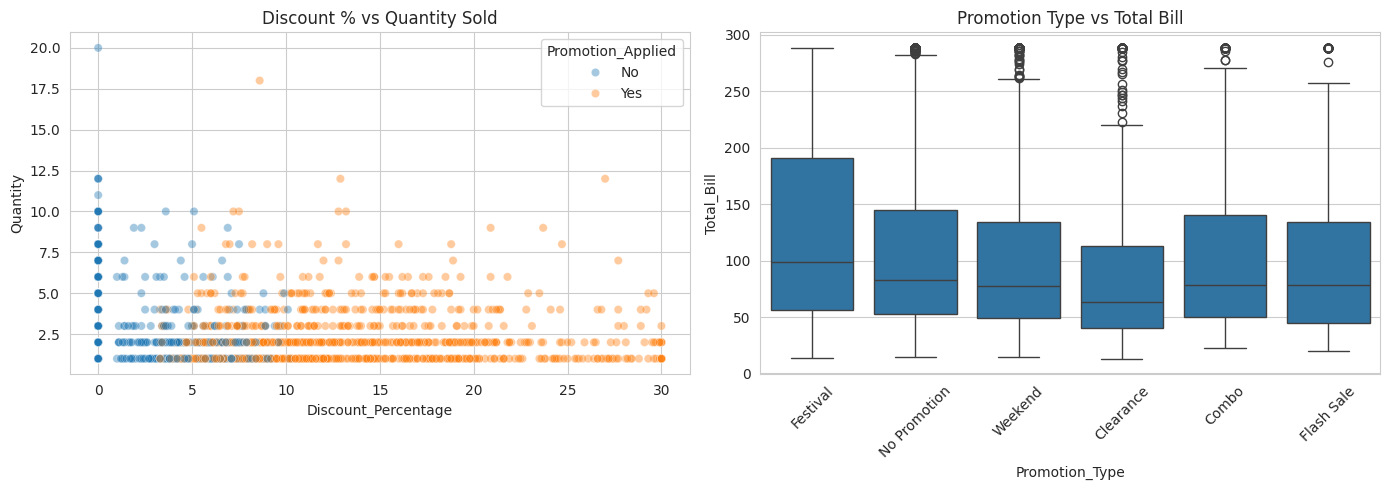

In [14]:
# =====================================================
# 4.8 DISCOUNT IMPACT
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df.sample(min(3000, len(df))),
                x='Discount_Percentage', y='Quantity',
                hue='Promotion_Applied', alpha=0.4, ax=axes[0])
axes[0].set_title("Discount % vs Quantity Sold")

sns.boxplot(data=df, x='Promotion_Type', y='Total_Bill', ax=axes[1])
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title("Promotion Type vs Total Bill")
plt.tight_layout(); plt.show()



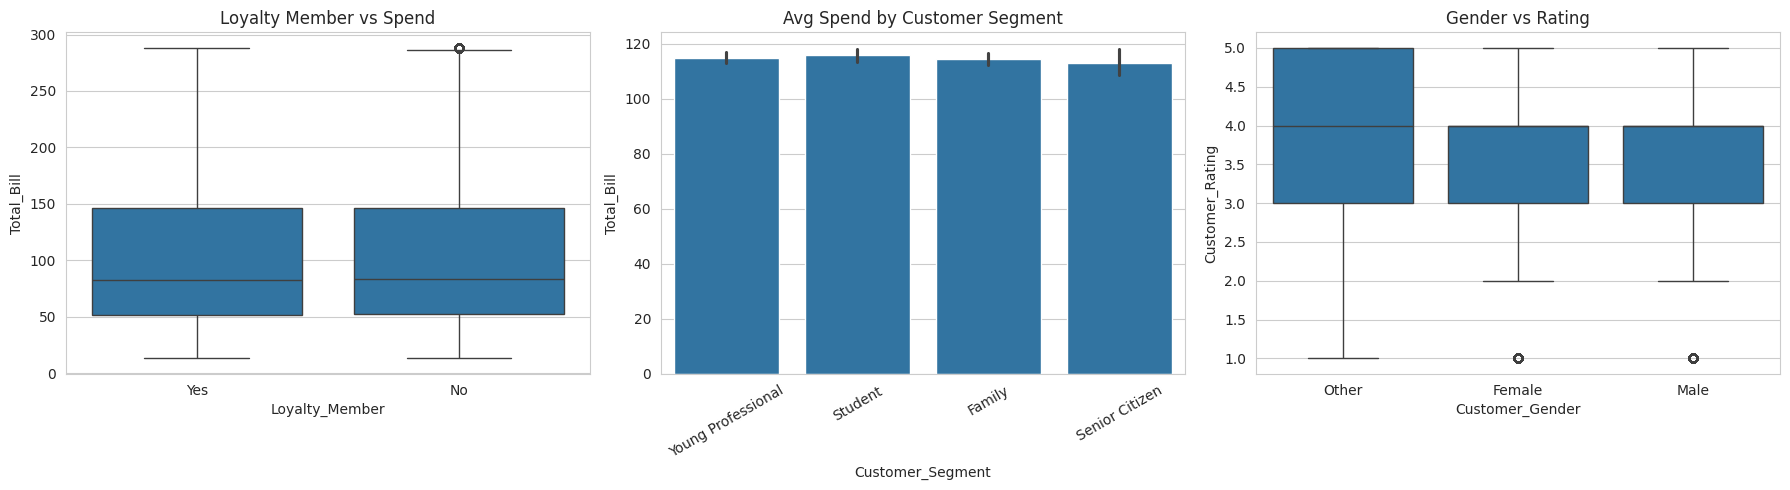

In [13]:
# =====================================================
# 4.9 CUSTOMER INSIGHTS (Loyalty, Segment, Gender)
# =====================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='Loyalty_Member', y='Total_Bill', ax=axes[0])
axes[0].set_title("Loyalty Member vs Spend")

sns.barplot(data=df, x='Customer_Segment', y='Total_Bill',
            estimator='mean', ax=axes[1])
axes[1].set_title("Avg Spend by Customer Segment")
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(data=df, x='Customer_Gender', y='Customer_Rating', ax=axes[2])
axes[2].set_title("Gender vs Rating")
plt.tight_layout(); plt.show()


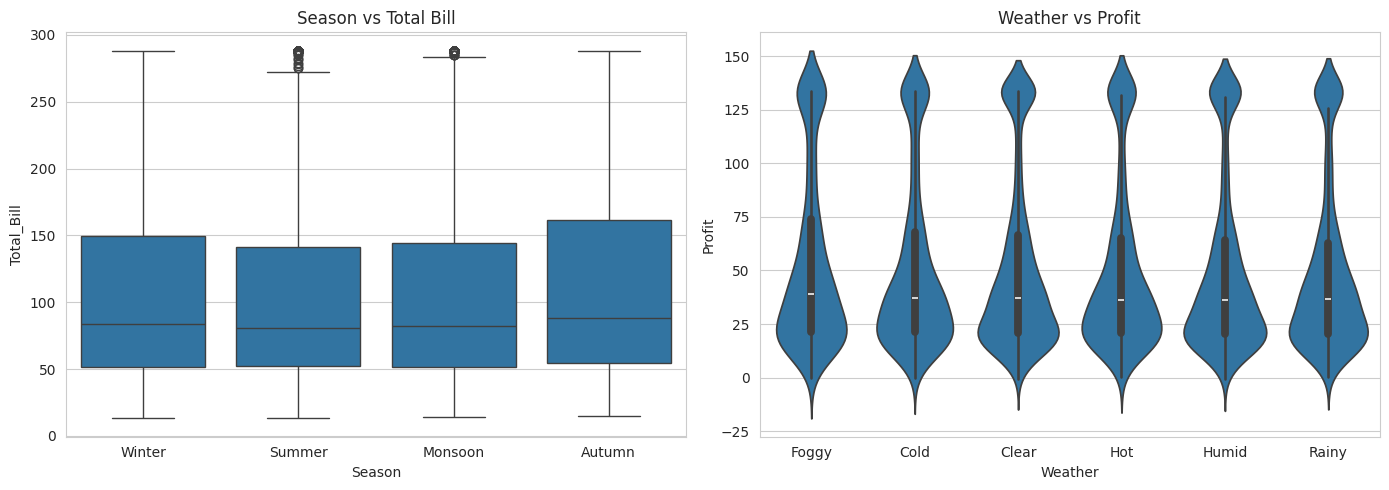

In [12]:
# =====================================================
# 4.10 WEATHER / SEASON IMPACT
# =====================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='Season', y='Total_Bill', ax=axes[0])
axes[0].set_title("Season vs Total Bill")
sns.violinplot(data=df, x='Weather', y='Profit', ax=axes[1])
axes[1].set_title("Weather vs Profit")
plt.tight_layout(); plt.show()